# HW3 — Barnstable and Long-Run Risk, VaR, and Decomposing Private Equity
**FINM 36700: Portfolio and Risk Management**
**Group Members: Ying Ding, Jiarui Feng, Hoang Pham, Nikita Rodin**

This notebook covers the graded parts of HW3:
- **Part A.** Case study [Barnstable and Long-Run Risk](https://markhendricks.github.io/finm-portfolio/case_studies/Barnstable%20and%20Long-Run%20Risk.html), Section 2 *Estimating Underperformance*. Section 1 is marked READING and is not included.
- **Part B.** Exercise [VaR of Equity Portfolio](https://markhendricks.github.io/finm-portfolio/exercises/VaR%20of%20Equity%20Portfolio.html).
- **Part C.** Exercise [Decomposing Private Equity](https://markhendricks.github.io/finm-portfolio/exercises/Decomposing%20PE.html).

Data, from the course [Box folder](https://uchicago.box.com/s/w3oqz9iy0kav3n3l4pa04p6etndo2ez2):
- `barnstable_analysis_data.xlsx`: monthly S&P 500 total returns (`SPX`) and 1-month T-bill rates (`TB1M`), 1926-01 to 2025-12. Used in Part A.
- `private_equity_data.xlsx`: weekly returns for public and private-equity tickers, 2015-01 to 2025-10. Used in Parts B and C.

**AI disclosure.** Content drafted with AI assistance and reviewed by the group for accuracy.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import norm, binomtest
import statsmodels.api as sm

plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)

BARNSTABLE_FILE = Path('barnstable_analysis_data.xlsx')
PE_FILE = Path('private_equity_data.xlsx')
OUTPUT = Path('results')
OUTPUT.mkdir(exist_ok=True)

ANN_MONTHLY = 12   # Part A: monthly data
ANN_WEEKLY = 52    # Parts B and C: weekly data

# Part A — Barnstable: Estimating Underperformance

## Data and notation

- $r^m$: monthly S&P 500 total return (`SPX`). $r^f$: monthly 1-month T-bill rate (`TB1M`).
- $\tilde r^m \equiv r^m - r^f$: excess return in levels.
- $\texttt{r} \equiv \ln(1+r)$: log return. $\tilde{\texttt{r}}^m \equiv \texttt{r}^m - \texttt{r}^f$: excess log return.
- Annualization: mean $\times 12$, volatility $\times\sqrt{12}$.

Samples: 1965–1999 (Barnstable's estimation window), 2000–2025, and 1926–2025.

In [2]:
barnstable = pd.read_excel(BARNSTABLE_FILE, sheet_name='data', index_col='date')
barnstable.index = pd.to_datetime(barnstable.index)
barnstable = barnstable.sort_index()

rm, rf = barnstable['SPX'], barnstable['TB1M']
log_rm, log_rf = np.log1p(rm), np.log1p(rf)

series = pd.DataFrame({
    ('levels', 'r^m'): rm,
    ('levels', 'excess r^m'): rm - rf,
    ('levels', 'r^f'): rf,
    ('logs', 'log r^m'): log_rm,
    ('logs', 'excess log r^m'): log_rm - log_rf,
    ('logs', 'log r^f'): log_rf,
})

SAMPLES = {'1965-1999': ('1965', '1999'), '2000-2025': ('2000', '2025'),
           '1926-2025': ('1926', '2025')}

def sample(data, label, samples=SAMPLES):
    start, end = samples[label]
    return data.loc[start:end]

print(f'{len(barnstable)} months: {barnstable.index[0]:%Y-%m} to {barnstable.index[-1]:%Y-%m}')
print({label: len(sample(barnstable, label)) for label in SAMPLES})

1200 months: 1926-01 to 2025-12
{'1965-1999': 420, '2000-2025': 312, '1926-2025': 1200}


## 2.1 Summary statistics (annualized)

In [3]:
def annualized_mean_vol(data, ann=ANN_MONTHLY):
    return pd.DataFrame({'mean': data.mean() * ann, 'vol': data.std(ddof=1) * np.sqrt(ann)})

summary_a = pd.concat({label: annualized_mean_vol(sample(series, label)) for label in SAMPLES}, axis=1)
summary_a.index.names = ['', 'series']
summary_a.to_csv(OUTPUT / 'a1_summary_stats.csv')
display(summary_a.style.format('{:.2%}'))

**Full sample vs. sub-samples.**
- Equity volatility is about 15% in both sub-samples (14.9% in 1965–1999 and 15.1% in 2000–2025). The full sample is higher, at 18.6%, because it includes the Great Depression and the 1930s.
- Total market returns vary a lot across samples: 12.9% in 1965–1999 and 9.1% in 2000–2025. Most of this gap comes from the risk-free rate, which averaged 6.2% in 1965–1999 and only 1.8% in 2000–2025.
- The equity premium is much more stable. Excess level returns are 6.8% (1965–1999), 7.3% (2000–2025), and 8.4% (1926–2025). So the 2000–2025 period was weak for stocks in total-return terms, but it was not weak relative to T-bills.

**Levels vs. logs.**
- Log means are below level means by about $\tfrac{1}{2}\sigma^2$. For 1965–1999 the S&P mean falls from 12.9% to 11.8%, and $\tfrac{1}{2}(0.149)^2 \approx 1.1\%$. The gap is largest in the full sample because volatility is highest there.
- Volatilities are almost identical in levels and logs, since $\ln(1+r)\approx r$ for monthly returns.
- For T-bills, levels and logs are nearly the same: the rate is small and has very low volatility.

## 2.2 Probability of underperformance

Cumulative returns compound, so cumulative log returns are sums of one-period log returns:

$$
R^m_{t,t+h} < R^f_{t,t+h}
\iff \sum_{i=1}^{h}\texttt{r}^m_{t+i} < \sum_{i=1}^{h}\texttt{r}^f_{t+i}
\iff \bar{\tilde{\texttt{r}}}^m_{t,t+h} < 0 .
$$

Assume annual excess log returns are i.i.d. $\mathcal{N}(\tilde\mu, \tilde\sigma^2)$. Then the $h$-year average is $\bar{\tilde{\texttt{r}}}^m_{t,t+h}\sim\mathcal{N}(\tilde\mu, \tilde\sigma^2/h)$, and

$$
p(h) = \Pr\left[\bar{\tilde{\texttt{r}}}^m_{t,t+h} < 0\right]
= \Phi_{\mathcal N}\left(\frac{0-\tilde\mu}{\tilde\sigma/\sqrt h}\right)
= \Phi_{\mathcal N}\left(-\sqrt{h}\,\text{SR}\right),
$$

where $\text{SR} = \tilde\mu/\tilde\sigma$ is the annualized Sharpe ratio of excess log market returns and $h$ is in years.

### 2.2.1 Estimate using 1965–1999

In [4]:
def log_sharpe(label, samples=SAMPLES):
    x = sample(series[('logs', 'excess log r^m')], label, samples)
    mu, sigma = x.mean() * ANN_MONTHLY, x.std(ddof=1) * np.sqrt(ANN_MONTHLY)
    return mu, sigma, mu / sigma

def prob_underperform(h, sharpe):
    return norm.cdf(-np.sqrt(h) * sharpe)

mu_is, sigma_is, sr_is = log_sharpe('1965-1999')
print(f'1965-1999 excess log return: mean {mu_is:.2%}, vol {sigma_is:.2%}, Sharpe ratio {sr_is:.4f}')

1965-1999 excess log return: mean 5.63%, vol 15.03%, Sharpe ratio 0.3746


### 2.2.2 Probability for $h = 15$ and $h = 30$ years

In [5]:
horizons = [1, 5, 10, 15, 20, 30]
prob_is = pd.Series({h: prob_underperform(h, sr_is) for h in horizons}, name='Pr[R^m < R^f], 1965-1999 estimates')
prob_is.index.name = 'h (years)'
display(prob_is.to_frame().style.format('{:.4%}'))
print(f'h = 15: {prob_is[15]:.4%}    h = 30: {prob_is[30]:.4%}')

,"Pr[R^m < R^f], 1965-1999 estimates"
h (years),
1,35.3970%
5,20.1103%
10,11.8074%
15,7.3402%
20,4.6930%
30,2.0089%


h = 15: 7.3402%    h = 30: 2.0089%


Based on the 1965–1999 estimates, the chance that stocks underperform T-bills is about 7.3% over 15 years and 2.0% over 30 years. Over one year the chance is 35%. The probability falls as the horizon grows because the mean of the cumulative excess return grows with $h$, while its volatility grows only with $\sqrt h$.

### 2.2.3 Probability as a function of the horizon

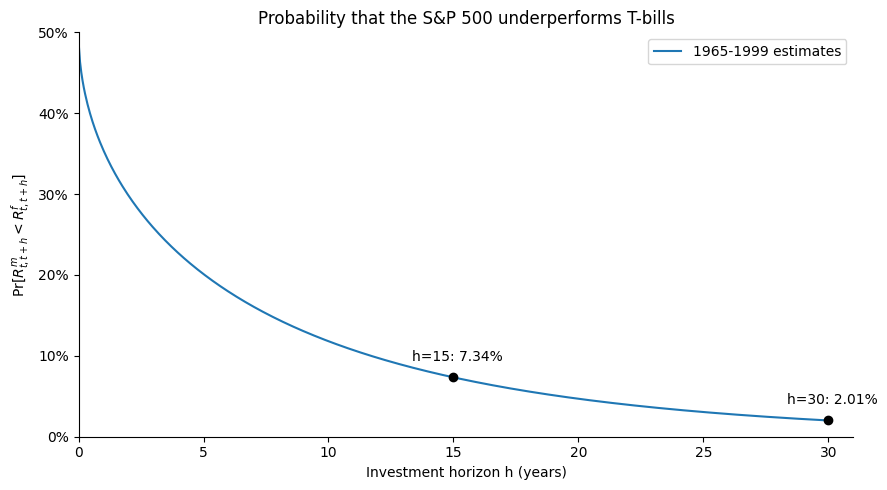

In [6]:
h_grid = np.linspace(0.01, 30, 600)
fig, ax = plt.subplots()
ax.plot(h_grid, prob_underperform(h_grid, sr_is), label='1965-1999 estimates')
for h in (15, 30):
    ax.scatter(h, prob_underperform(h, sr_is), color='black', zorder=3)
    ax.annotate(f'h={h}: {prob_underperform(h, sr_is):.2%}', (h, prob_underperform(h, sr_is)),
                textcoords='offset points', xytext=(-30, 12))
ax.set_xlabel('Investment horizon h (years)')
ax.set_ylabel(r'$\Pr[R^m_{t,t+h} < R^f_{t,t+h}]$')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlim(0, 31)
ax.set_ylim(0, 0.5)
ax.set_title('Probability that the S&P 500 underperforms T-bills')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / 'a2_prob_underperformance.png', dpi=160)
plt.show()

## 2.3 Full-sample analysis (1965–2025)

We re-estimate the Sharpe ratio of excess log returns on 1965–2025. At the end of 2025, we then compute the probability that the market underperforms T-bills over the next $h$ years, for $0 < h \le 30$.

,1965-1999,1965-2025
Mean excess log return,5.6301%,5.8215%
Vol excess log return,15.0286%,15.1141%
Sharpe ratio,0.3746,0.3852
p(h=15),7.3402%,6.7883%
p(h=30),2.0089%,1.7444%


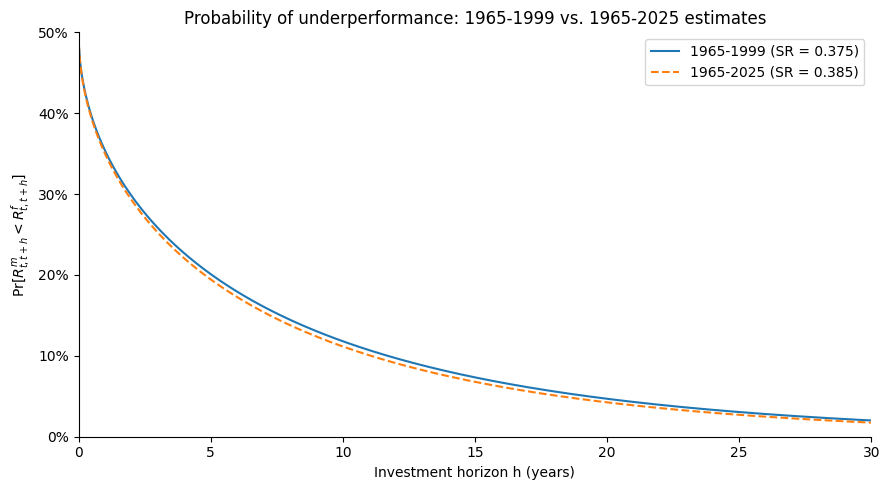

In [7]:
LONG_SAMPLE = {'1965-2025': ('1965', '2025')}
mu_full, sigma_full, sr_full = log_sharpe('1965-2025', LONG_SAMPLE)

estimates = pd.DataFrame({
    '1965-1999': [mu_is, sigma_is, sr_is, prob_underperform(15, sr_is), prob_underperform(30, sr_is)],
    '1965-2025': [mu_full, sigma_full, sr_full, prob_underperform(15, sr_full), prob_underperform(30, sr_full)],
}, index=['Mean excess log return', 'Vol excess log return', 'Sharpe ratio', 'p(h=15)', 'p(h=30)'])
estimates.to_csv(OUTPUT / 'a3_full_sample_probability.csv')
display(estimates.style.format('{:.4%}').format('{:.4f}', subset=pd.IndexSlice['Sharpe ratio', :]))

fig, ax = plt.subplots()
ax.plot(h_grid, prob_underperform(h_grid, sr_is), label=f'1965-1999 (SR = {sr_is:.3f})')
ax.plot(h_grid, prob_underperform(h_grid, sr_full), ls='--', label=f'1965-2025 (SR = {sr_full:.3f})')
ax.set_xlabel('Investment horizon h (years)')
ax.set_ylabel(r'$\Pr[R^m_{t,t+h} < R^f_{t,t+h}]$')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlim(0, 30)
ax.set_ylim(0, 0.5)
ax.set_title('Probability of underperformance: 1965-1999 vs. 1965-2025 estimates')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / 'a3_prob_underperformance_full.png', dpi=160)
plt.show()

Using 1965–2025, the Sharpe ratio of excess log returns is 0.385, slightly above the 0.375 from 1965–1999. Over 2000–2025 the excess return was a bit higher and volatility was about the same. As of the end of 2025, the probability that stocks underperform T-bills over the next 30 years is about 1.7%, compared with 2.0% under the 1999 estimates. The two curves are almost the same. Adding 26 years of data barely changes the long-run conclusion.

The estimate still relies on strong assumptions: i.i.d. normal log returns, a constant Sharpe ratio, and a sample mean measured without error. With $\tilde\sigma\approx15\%$ and 61 years of data, the standard error of $\tilde\mu$ is about $15\%/\sqrt{61}\approx 1.9\%$. That error is large relative to a mean of about 5.8%. Since $p(30)$ depends on $\sqrt{30}\,\text{SR}$, it is very sensitive to this estimation error.

## 2.4 In-sample estimate of out-of-sample likelihood

Using the 1999 estimates, what was the probability that the $h$-year market return would be lower than the one realized in 2000–2025 ($h = 26$)? With log market returns,

$$
p = \Phi_{\mathcal N}\left(\sqrt{h}\,\frac{\bar{\texttt{r}}_{\text{out-of-sample}} - \bar{\texttt{r}}_{\text{in-sample}}}{\sigma_{\text{in-sample}}}\right).
$$

In [8]:
H_OOS = 26
mkt_log = series[('logs', 'log r^m')]
mkt_excess_log = series[('logs', 'excess log r^m')]

def oos_probability(x, h=H_OOS):
    x_in, x_out = sample(x, '1965-1999'), sample(x, '2000-2025')
    mean_in, mean_out = x_in.mean() * ANN_MONTHLY, x_out.mean() * ANN_MONTHLY
    sigma_in = x_in.std(ddof=1) * np.sqrt(ANN_MONTHLY)
    return {'In-sample mean (1965-1999)': mean_in, 'In-sample vol (1965-1999)': sigma_in,
            'Realized mean (2000-2025)': mean_out,
            'Probability': norm.cdf(np.sqrt(h) * (mean_out - mean_in) / sigma_in)}

oos_table = pd.DataFrame({'Log market return': oos_probability(mkt_log),
                          'Excess log market return': oos_probability(mkt_excess_log)})
oos_table.to_csv(OUTPUT / 'a4_oos_probability.csv')
display(oos_table.style.format('{:.2%}'))

,Log market return,Excess log market return
In-sample mean (1965-1999),11.76%,5.63%
In-sample vol (1965-1999),14.96%,15.03%
Realized mean (2000-2025),7.90%,6.08%
Probability,9.43%,56.05%


Based on the 1999 estimates ($\bar{\texttt{r}}^m = 11.8\%$, $\sigma = 15.0\%$), the probability that the 26-year market return would be at or below the realized 2000–2025 value (7.9% per year in logs) was only about **9.4%**. In total-return terms, the market did much worse than Barnstable expected.

The second column shows the main reason. The excess log return in 2000–2025 (6.1%) was actually above the 1965–1999 estimate (5.6%), so that probability is about 56%. The shortfall in total returns came almost entirely from the drop in the risk-free rate, not from a weak equity premium.

This matters for Barnstable. Both proposals bet that the S&P beats a **fixed 6% hurdle**, not the T-bill rate. A fixed hurdle therefore carries interest-rate risk that the "stocks beat T-bills in the long run" argument ignores.

# Part B — VaR of Equity Portfolio

**Data.** Weekly returns from the `total returns` sheet of `private_equity_data.xlsx`. We use the four listed alternative-asset managers: `APO` (Apollo), `BX` (Blackstone), `KKR` (KKR), and `CG` (Carlyle). The sample runs from 2015-01-09 to 2025-10-03 (561 weeks).

Volatility is annualized with $\sqrt{52}$. VaR and CVaR are weekly return quantities ($q = 0.05$) and are not annualized. Losses appear as negative returns.

In [9]:
TICKERS = ['APO', 'BX', 'KKR', 'CG']
Q = 0.05

pe_total = pd.read_excel(PE_FILE, sheet_name='total returns', index_col='date')
pe_total.index = pd.to_datetime(pe_total.index)
pe_total = pe_total.sort_index()
stocks = pe_total[TICKERS]

print(f'{len(stocks)} weeks: {stocks.index[0]:%Y-%m-%d} to {stocks.index[-1]:%Y-%m-%d}')
display(stocks.corr().style.format('{:.2f}').set_caption('Correlation of weekly returns'))

561 weeks: 2015-01-09 to 2025-10-03


,APO,BX,KKR,CG
APO,1.00,0.69,0.76,0.71
BX,0.69,1.00,0.76,0.75
KKR,0.76,0.76,1.00,0.76
CG,0.71,0.75,0.76,1.00


## 1. Diversification

### 1.1 Stand-alone statistics (full sample)

Empirical VaR is the 5% sample quantile, $\widehat{\text{VaR}}_{.05} = \hat F^{-1}(.05)$. Empirical CVaR is the average return at or below it, $\widehat{\text{CVaR}}_{.05} = \hat{\mathbb E}[r \mid r \le \widehat{\text{VaR}}_{.05}]$.

In [10]:
def risk_stats(returns, q=Q, ann=ANN_WEEKLY):
    rows = {}
    for col in returns.columns:
        x = returns[col].dropna()
        var = x.quantile(q)
        rows[col] = {'Volatility (weekly)': x.std(ddof=1),
                     'Volatility (annualized)': x.std(ddof=1) * np.sqrt(ann),
                     'Empirical VaR (.05)': var,
                     'Empirical CVaR (.05)': x[x <= var].mean()}
    return pd.DataFrame(rows).T

stats_b11 = risk_stats(stocks)
stats_b11.to_csv(OUTPUT / 'b1_1_standalone_risk.csv')
display(stats_b11.style.format('{:.2%}'))

,Volatility (weekly),Volatility (annualized),Empirical VaR (.05),Empirical CVaR (.05)
APO,5.10%,36.81%,-7.53%,-10.82%
BX,4.97%,35.86%,-7.21%,-10.20%
KKR,5.07%,36.53%,-7.38%,-10.79%
CG,5.10%,36.74%,-8.01%,-10.94%


### 1.2 Equally-weighted portfolio

In [11]:
weights_ew = pd.Series(1 / len(TICKERS), index=TICKERS)
port_ew = (stocks @ weights_ew).rename('EW portfolio')

stats_b12 = pd.concat([stats_b11, risk_stats(port_ew.to_frame())])
stats_b12.loc['Average of 4 stocks'] = stats_b11.mean()
stats_b12.to_csv(OUTPUT / 'b1_2_ew_portfolio_risk.csv')
display(stats_b12.style.format('{:.2%}'))

corr_pairs = stocks.corr().where(np.triu(np.ones((4, 4), dtype=bool), k=1)).stack()
print(f'Average pairwise correlation: {corr_pairs.mean():.3f} (range {corr_pairs.min():.2f} to {corr_pairs.max():.2f})')

,Volatility (weekly),Volatility (annualized),Empirical VaR (.05),Empirical CVaR (.05)
APO,5.10%,36.81%,-7.53%,-10.82%
BX,4.97%,35.86%,-7.21%,-10.20%
KKR,5.07%,36.53%,-7.38%,-10.79%
CG,5.10%,36.74%,-8.01%,-10.94%
EW portfolio,4.54%,32.71%,-6.90%,-9.88%
Average of 4 stocks,5.06%,36.49%,-7.53%,-10.69%


Average pairwise correlation: 0.738 (range 0.69 to 0.76)


The EW portfolio is less risky than every single stock on every measure. Its volatility is 32.7% vs. 35.9%–36.8%, its VaR is −6.9% vs. −7.2% to −8.0%, and its CVaR is −9.9% vs. −10.2% to −10.9%. Relative to the average stock, diversification cuts volatility by about 10% and VaR/CVaR by about 7%–8%.

The benefit is **small** because the four names are highly correlated: pairwise correlations are between 0.69 and 0.76, with an average of 0.74. With equal weights, similar volatilities $\sigma$, and average correlation $\bar\rho$, portfolio volatility is about $\sigma\sqrt{1/n + (1-1/n)\bar\rho} = \sigma\sqrt{0.25 + 0.75(0.74)} \approx 0.90\,\sigma$. That matches the result above. All four firms are listed alternative-asset managers. They share the same exposures to the equity market, credit conditions, fundraising, and deal flow. Most of their risk is this common factor, which cannot be diversified away within the group.

### 1.3 Dropping the most volatile asset

The most volatile stock gets weight 0. The other three keep weight 1/4 each, so 75% is invested (the 25% left over is like a negligible risk-free position).

In [12]:
most_volatile = stats_b11['Volatility (weekly)'].idxmax()
weights_drop = weights_ew.copy()
weights_drop[most_volatile] = 0.0
port_drop = (stocks @ weights_drop).rename(f'EW ex-{most_volatile} (weight 0)')

stats_b13 = pd.concat([risk_stats(port_ew.to_frame()), risk_stats(port_drop.to_frame())])
stats_b13.loc['Change from removing ' + most_volatile] = stats_b13.iloc[1] - stats_b13.iloc[0]
stats_b13.loc[f'Stand-alone {most_volatile} x 1/4'] = stats_b11.loc[most_volatile] * weights_ew[most_volatile]
stats_b13.to_csv(OUTPUT / 'b1_3_drop_most_volatile.csv')
print(f'Most volatile asset: {most_volatile}')
display(stats_b13.style.format('{:.2%}'))

Most volatile asset: APO


,Volatility (weekly),Volatility (annualized),Empirical VaR (.05),Empirical CVaR (.05)
EW portfolio,4.54%,32.71%,-6.90%,-9.88%
EW ex-APO (weight 0),3.47%,24.99%,-5.36%,-7.43%
Change from removing APO,-1.07%,-7.72%,1.54%,2.45%
Stand-alone APO x 1/4,1.28%,9.20%,-1.88%,-2.71%


APO has the highest full-sample volatility (36.81% annualized), but only barely: CG is at 36.74% and KKR at 36.53%. Replacing APO with zero changes the portfolio as follows:
- volatility falls from 32.7% to 25.0% (−7.7 pp annualized, about 24% of portfolio volatility),
- VaR improves from −6.9% to −5.4% (+1.5 pp per week),
- CVaR improves from −9.9% to −7.4% (+2.5 pp per week).

The stand-alone view would assign APO about $\tfrac14 \times 36.8\% \approx 9.2$ pp of volatility, $\tfrac14\times 7.5\% \approx 1.9$ pp of VaR, and $\tfrac14 \times 10.8\% \approx 2.7$ pp of CVaR. The marginal contribution is **somewhat smaller** than this, mainly for volatility and VaR, because some of APO's risk diversifies away. Still, APO adds about 24% of portfolio volatility, which is close to its 25% weight. With correlations near 0.75, very little of its risk is diversified. Because the four stocks have almost the same volatility and correlations, the "most volatile" asset is not special. Removing any of them would reduce risk by a similar amount, mostly because 25% less capital is exposed to the common factor.

## 2. Dynamic measures

### 2.1 Conditional statistics of the EW portfolio at the end of the sample

We assume a zero weekly mean, so the variance estimate is the average squared return. $\sigma_t$ uses data through $t-1$ only:

$$
\sigma^2_{t,\text{rolling}} = \frac{1}{m}\sum_{i=1}^{m} r^2_{t-i},\quad m = 26,
\qquad\qquad
\sigma^2_{t,\text{expanding}} = \frac{1}{t-1}\sum_{i=1}^{t-1} r^2_{i}.
$$

Normal VaR and CVaR with $\mu = 0$, $q = .05$, $\tau = 1$ week, and $\texttt{z}_{.05} = -1.65$:

$$
\text{VaR}_{.05} = \texttt{z}_{.05}\,\sigma_t, \qquad
\text{CVaR}_{.05} = -\frac{\phi(\texttt{z}_{.05})}{.05}\,\sigma_t \approx -2.05\,\sigma_t .
$$

"As of the end of the sample" means the forecast made with the last 26 weeks (2025-04-11 to 2025-10-03) for the next week.

In [13]:
WINDOW = 26
Z_Q = -1.65
CVAR_MULT = -norm.pdf(Z_Q) / Q

assets_b2 = pd.concat([stocks, port_ew], axis=1)
sigma_rolling = np.sqrt((assets_b2 ** 2).rolling(WINDOW).mean().shift(1))
sigma_expanding = np.sqrt((assets_b2 ** 2).expanding(min_periods=WINDOW).mean().shift(1))
sigma_end = np.sqrt((assets_b2 ** 2).iloc[-WINDOW:].mean())

conditional_end = pd.DataFrame({'Volatility (annualized)': sigma_end * np.sqrt(ANN_WEEKLY),
                                'Normal VaR (.05)': Z_Q * sigma_end,
                                'Normal CVaR (.05)': CVAR_MULT * sigma_end})

compare_b21 = pd.DataFrame({
    'Conditional, rolling 26w (2.1)': conditional_end.loc['EW portfolio'].values,
    'Unconditional, empirical (1.2)': stats_b12.loc['EW portfolio', ['Volatility (annualized)',
                                       'Empirical VaR (.05)', 'Empirical CVaR (.05)']].values,
}, index=['Volatility (annualized)', 'VaR (.05)', 'CVaR (.05)'])

conditional_end.to_csv(OUTPUT / 'b2_1_conditional_var.csv')
print(f'CVaR multiplier: {CVAR_MULT:.4f}')
display(conditional_end.style.format('{:.2%}').set_caption('Conditional estimates as of 2025-10-03, all series'))
display(compare_b21.style.format('{:.2%}').set_caption('EW portfolio: conditional vs. unconditional'))

CVaR multiplier: -2.0453


,Volatility (annualized),Normal VaR (.05),Normal CVaR (.05)
APO,37.09%,-8.49%,-10.52%
BX,28.76%,-6.58%,-8.16%
KKR,35.89%,-8.21%,-10.18%
CG,38.03%,-8.70%,-10.79%
EW portfolio,31.90%,-7.30%,-9.05%


,"Conditional, rolling 26w (2.1)","Unconditional, empirical (1.2)"
Volatility (annualized),31.90%,32.71%
VaR (.05),-7.30%,-6.90%
CVaR (.05),-9.05%,-9.88%


At the end of the sample, the conditional EW-portfolio volatility is 31.9%, close to the full-sample 32.7%. The last six months were a fairly typical volatility regime for this group, so the conditional and unconditional numbers are similar:
- **VaR:** normal conditional VaR is −7.3% vs. the empirical −6.9%. It is slightly more severe because $1.65\,\sigma$ is a bit beyond the empirical 5% quantile here.
- **CVaR:** normal conditional CVaR is −9.05%, less severe than the empirical −9.9%. Weekly returns are fat-tailed (for example, the March 2020 crash), and a normal distribution understates losses beyond the VaR.

The conditional estimates do not stay this close all the time. The plot in 2.2 shows rolling volatility moving well above and below the unconditional level, so conditional VaR can differ a lot from the static estimate at other dates.

### 2.2 Hit-test backtest

A hit at week $t$ means $r_t < \texttt{z}_{.05}\,\sigma_t$, where $\sigma_t$ uses data only through $t-1$. Both methods use the same evaluation window: weeks where 26 weeks of history exist (2015-07-10 to 2025-10-03, 535 weeks). A well-calibrated 5% VaR should be hit about 5% of the time. The p-value comes from a two-sided binomial test of $H_0$: hit rate $= 5\%$.

In [14]:
eval_idx = sigma_rolling.dropna().index.intersection(sigma_expanding.dropna().index)
returns_eval = assets_b2.loc[eval_idx]
var_paths = {'Expanding': Z_Q * sigma_expanding.loc[eval_idx], 'Rolling (26w)': Z_Q * sigma_rolling.loc[eval_idx]}

rows = {}
for method, var_path in var_paths.items():
    hits = returns_eval < var_path
    for col in assets_b2.columns:
        n_hits = int(hits[col].sum())
        rows[(col, method)] = {'Hits': n_hits, 'Weeks': len(eval_idx), 'Hit rate': n_hits / len(eval_idx),
                               'Binomial p-value': binomtest(n_hits, len(eval_idx), Q).pvalue}
hit_table = pd.DataFrame(rows).T
hit_table[['Hits', 'Weeks']] = hit_table[['Hits', 'Weeks']].astype(int)
hit_table.index.names = ['Series', 'Volatility']
hit_table.to_csv(OUTPUT / 'b2_2_hit_test.csv')
print(f'Evaluation window: {eval_idx[0]:%Y-%m-%d} to {eval_idx[-1]:%Y-%m-%d} ({len(eval_idx)} weeks)')
display(hit_table.loc['EW portfolio'].style.format({'Hit rate': '{:.2%}', 'Binomial p-value': '{:.3f}'})
        .set_caption('EW portfolio'))
display(hit_table.drop('EW portfolio', level='Series').style.format({'Hit rate': '{:.2%}', 'Binomial p-value': '{:.3f}'})
        .set_caption('Individual stocks (for reference)'))

Evaluation window: 2015-07-10 to 2025-10-03 (535 weeks)


,Hits,Weeks,Hit rate,Binomial p-value
Volatility,,,,
Expanding,31,535,5.79%,0.372
Rolling (26w),28,535,5.23%,0.766


,,Hits,Weeks,Hit rate,Binomial p-value
Series,Volatility,,,,
APO,Expanding,30,535,5.61%,0.487
BX,Expanding,28,535,5.23%,0.766
KKR,Expanding,31,535,5.79%,0.372
CG,Expanding,33,535,6.17%,0.232
APO,Rolling (26w),26,535,4.86%,1.000
BX,Rolling (26w),27,535,5.05%,0.921
KKR,Rolling (26w),29,535,5.42%,0.620
CG,Rolling (26w),37,535,6.92%,0.047


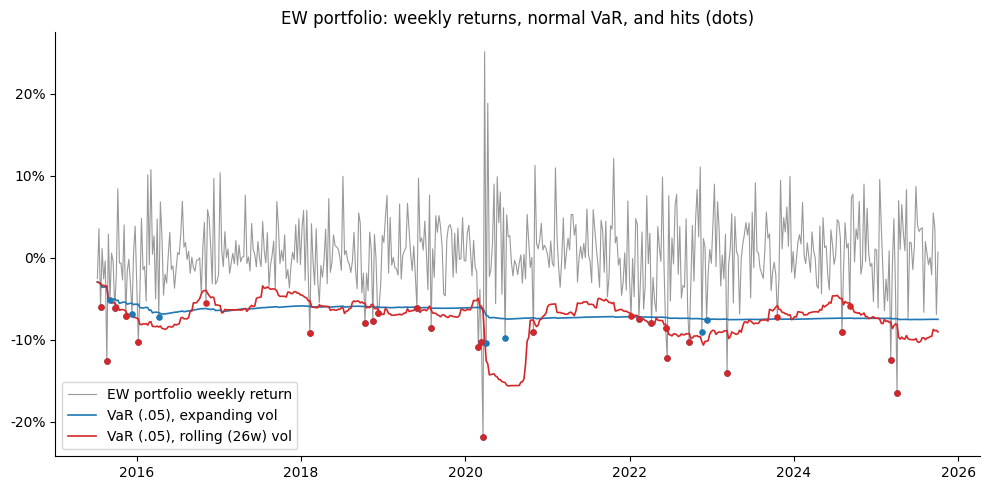

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
port_eval = returns_eval['EW portfolio']
ax.plot(port_eval.index, port_eval, color='0.6', lw=0.8, label='EW portfolio weekly return')
for (method, var_path), color in zip(var_paths.items(), ['tab:blue', 'tab:red']):
    ax.plot(var_path.index, var_path['EW portfolio'], color=color, lw=1.2, label=f'VaR (.05), {method.lower()} vol')
    hit_mask = port_eval < var_path['EW portfolio']
    ax.scatter(port_eval.index[hit_mask], port_eval[hit_mask], color=color, s=14, zorder=3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_title('EW portfolio: weekly returns, normal VaR, and hits (dots)')
ax.legend(loc='lower left')
fig.tight_layout()
fig.savefig(OUTPUT / 'b2_2_var_backtest.png', dpi=160)
plt.show()

For the EW portfolio, the **rolling** VaR is hit 5.23% of the time (28 of 535 weeks). The **expanding** VaR is hit 5.79% of the time (31 of 535). Neither rate is statistically different from 5% (p-values 0.77 and 0.37), so both pass the unconditional hit test.

The two methods still behave differently, as the plot shows:
- After its first year, the expanding estimate hardly moves (26%–33% annualized). It is too low in long high-volatility periods and too conservative in calm ones. Its hits pile up in stress episodes, for example 5 hits from February to June 2020 and 7 in 2022. Its overall hit rate is near 5% only because these errors offset across the sample.
- The rolling estimate ranges from about 13% to 68% annualized and follows the current regime. It still misses the first week of a sudden shock (both methods are hit in 2018 Q4, March 2020, and April 2025), but its VaR widens quickly afterwards. It has fewer repeated hits once a stress period is under way (3 in 2020, 6 in 2022), and its hit rate is closer to 5%.

The hit test only checks the average rate, not whether hits cluster, so it cannot fully separate the two methods. The plot suggests the rolling estimate is better calibrated at each point in time.

# Part C — Decomposing Private Equity

**Data.** `private_equity_data.xlsx`, weekly, 2015-01-09 to 2025-10-03 (561 weeks). We use the `excess returns` sheet, which is total returns minus `SHV` (short-term Treasury ETF, the risk-free proxy). Annualization uses 52: mean $\times 52$, volatility $\times \sqrt{52}$, alpha $\times 52$.

**Data note.** In this file, the `total returns` sheet equals the week-over-week change of the `prices` sheet, and the prices are unadjusted closes. So the returns do not include distributions. This hardly matters for the equity names, but the income-oriented ETFs (`AGG`, `HYG`, `IEF`, and `SHV`) leave out most of their return. Their means below are understated, and `SHV` is nearly zero.

In [16]:
pe_info = pd.read_excel(PE_FILE, sheet_name='descriptions').set_index('ticker')
pe_excess = pd.read_excel(PE_FILE, sheet_name='excess returns', index_col='date')
pe_excess.index = pd.to_datetime(pe_excess.index)
pe_excess = pe_excess.sort_index()

print(f'{len(pe_excess)} weeks: {pe_excess.index[0]:%Y-%m-%d} to {pe_excess.index[-1]:%Y-%m-%d}')
display(pe_info[['shortName', 'quoteType']])

561 weeks: 2015-01-09 to 2025-10-03


,shortName,quoteType
ticker,,
SPY,SPDR S&P 500,ETF
VTV,Vanguard Value ETF,ETF
AGG,iShares Core U.S. Aggregate Bon,ETF
HYG,iShares iBoxx $ High Yield Corp,ETF
IEF,iShares 7-10 Year Treasury Bond,ETF
PSP,Invesco Global Listed Private E,ETF
PEX,ProShares Global Listed Private,ETF
APO,"Apollo Global Management, Inc.",EQUITY
BX,Blackstone Inc.,EQUITY


## 1. Performance

**Stand-alone:** annualized mean excess return, volatility, and Sharpe ratio.

**Linear decomposition** against the market (`SPY`):

$$\tilde r^{i}_t = \alpha^i + \beta^i\,\tilde r^{SPY}_t + \epsilon^i_t,
\qquad \text{IR}^i = \frac{\alpha^i}{\sigma(\epsilon^i)} .$$

`SPY` is the regressor, so it is left out of the decomposition table (its beta is 1 and its alpha and residual are 0 by construction).

In [17]:
def standalone_stats(returns, ann=ANN_WEEKLY):
    mean = returns.mean() * ann
    vol = returns.std(ddof=1) * np.sqrt(ann)
    return pd.DataFrame({'Mean': mean, 'Volatility': vol, 'Sharpe': mean / vol})

def decomposition(returns, factors, ann=ANN_WEEKLY):
    X = sm.add_constant(factors)
    rows = {}
    for col in returns.columns:
        model = sm.OLS(returns[col], X).fit()
        alpha = model.params['const'] * ann
        resid_vol = model.resid.std(ddof=1) * np.sqrt(ann)
        row = {'Alpha': alpha}
        row.update({f'Beta {f}': model.params[f] for f in factors.columns})
        row.update({'Info ratio': alpha / resid_vol, 'R-squared': model.rsquared,
                    'Alpha t-stat': model.tvalues['const']})
        rows[col] = row
    return pd.DataFrame(rows).T

stats_c1 = standalone_stats(pe_excess)
decomp_c1 = decomposition(pe_excess.drop(columns='SPY'), pe_excess[['SPY']])
stats_c1.to_csv(OUTPUT / 'c1_standalone_stats.csv')
decomp_c1.to_csv(OUTPUT / 'c1_spy_decomposition.csv')

display(stats_c1.style.format({'Mean': '{:.2%}', 'Volatility': '{:.2%}', 'Sharpe': '{:.3f}'})
        .set_caption('Stand-alone performance (annualized, excess returns)'))
display(decomp_c1.style.format({'Alpha': '{:.2%}', 'Beta SPY': '{:.3f}', 'Info ratio': '{:.3f}',
                                'R-squared': '{:.3f}', 'Alpha t-stat': '{:.2f}'})
        .set_caption('Linear decomposition on SPY (annualized alpha)'))

,Mean,Volatility,Sharpe
SPY,12.31%,16.97%,0.726
VTV,8.65%,16.41%,0.527
AGG,-0.79%,5.09%,-0.155
HYG,-0.47%,9.54%,-0.050
IEF,-0.73%,6.44%,-0.114
PSP,4.94%,23.17%,0.213
PEX,-1.43%,21.46%,-0.066
APO,23.15%,36.79%,0.629
BX,21.76%,35.82%,0.607
KKR,22.86%,36.50%,0.626


,Alpha,Beta SPY,Info ratio,R-squared,Alpha t-stat
VTV,-2.39%,0.896,-0.388,0.859,-1.27
AGG,-1.60%,0.066,-0.321,0.048,-1.05
HYG,-5.70%,0.424,-0.910,0.569,-2.97
IEF,-0.40%,-0.027,-0.062,0.005,-0.20
PSP,-9.60%,1.181,-0.826,0.748,-2.70
PEX,-13.46%,0.978,-0.988,0.597,-3.23
APO,4.93%,1.480,0.184,0.466,0.60
BX,3.74%,1.464,0.145,0.481,0.47
KKR,3.48%,1.574,0.140,0.536,0.46
CG,-3.59%,1.466,-0.133,0.459,-0.43


**Takeaways.**
- **Listed PE managers (APO, BX, KKR, CG)** had high average excess returns (14%–23%), but also about 36% volatility. Their Sharpe ratios (0.39–0.63) are all **below SPY's 0.73**. Market betas are around 1.5, and SPY explains about half of their variance ($R^2 \approx 0.46$–$0.54$). Most of their return is levered equity exposure.
- **Alpha is not reliable.** APO, BX, and KKR have positive alphas of 3.5%–4.9% per year, but information ratios are only 0.14–0.18 and alpha t-stats are below 1. CG's alpha is negative. Over about 11 years, we cannot reject zero alpha for any of them.
- **Listed-PE ETFs (PSP, PEX)** have betas of 1.0–1.2, **negative** alphas (−9.6% and −13.5%), and the lowest equity Sharpe ratios. They hold a broad, globally diversified basket of listed PE vehicles (including closed-end funds and BDCs), which did much worse than the S&P over this period.
- **Bonds (AGG, IEF, HYG)** have low or zero equity beta, except HYG ($\beta \approx 0.42$, $R^2 \approx 0.57$), which carries a lot of equity-like credit risk. Their negative means mostly reflect the missing coupons (see the data note).
- **VTV** (value) has beta 0.90, $R^2 = 0.86$, and negative alpha relative to SPY: value lagged growth over this period.

## 2. Replication of APO

We compare two in-sample linear replications of APO's excess return:

$$\text{(i)}\quad \tilde r^{APO}_t = \alpha + \beta^{SPY}\tilde r^{SPY}_t + \epsilon_t$$
$$\text{(ii)}\quad \tilde r^{APO}_t = \alpha + \beta^{SPY}\tilde r^{SPY}_t + \beta^{IEF}\tilde r^{IEF}_t + \beta^{HYG}\tilde r^{HYG}_t + \epsilon_t$$

In [18]:
TARGET = 'APO'
MODELS = {'SPY only': ['SPY'], 'SPY + IEF + HYG': ['SPY', 'IEF', 'HYG']}
y_apo = pe_excess[TARGET]

fits, rows = {}, {}
for name, regressors in MODELS.items():
    model = sm.OLS(y_apo, sm.add_constant(pe_excess[regressors])).fit()
    fits[name] = model
    resid_vol = model.resid.std(ddof=1) * np.sqrt(ANN_WEEKLY)
    row = {'Alpha (annualized)': model.params['const'] * ANN_WEEKLY, 'Alpha t-stat': model.tvalues['const']}
    for f in ['SPY', 'IEF', 'HYG']:
        row[f'Beta {f}'] = model.params.get(f, 0.0)
        row[f't-stat {f}'] = model.tvalues.get(f, 0.0)
    row.update({'R-squared': model.rsquared, 'Adj. R-squared': model.rsquared_adj,
                'Tracking error (annualized)': resid_vol,
                'Info ratio': model.params['const'] * ANN_WEEKLY / resid_vol,
                'Correlation(APO, replication)': np.corrcoef(y_apo, model.fittedvalues - model.params['const'])[0, 1]})
    rows[name] = row

replication = pd.DataFrame(rows)
replication.to_csv(OUTPUT / 'c2_apo_replication.csv')
pct_rows = ['Alpha (annualized)', 'Tracking error (annualized)']
display(replication.style.format('{:.3f}').format('{:.2%}', subset=pd.IndexSlice[pct_rows, :])
        .set_caption('APO replication (weekly excess returns; 0 = factor not included)'))

f_test = fits['SPY + IEF + HYG'].compare_f_test(fits['SPY only'])
print(f'F-test that IEF and HYG add nothing: F = {f_test[0]:.2f}, p-value = {f_test[1]:.2e}')

,SPY only,SPY + IEF + HYG
Alpha (annualized),4.93%,9.96%
Alpha t-stat,0.599,1.233
Beta SPY,1.480,1.066
t-stat SPY,22.086,10.429
Beta IEF,0.000,-0.704
t-stat IEF,0.000,-3.957
Beta HYG,0.000,0.931
t-stat HYG,0.000,5.106
R-squared,0.466,0.497
Adj. R-squared,0.465,0.494


F-test that IEF and HYG add nothing: F = 16.87, p-value = 7.68e-08


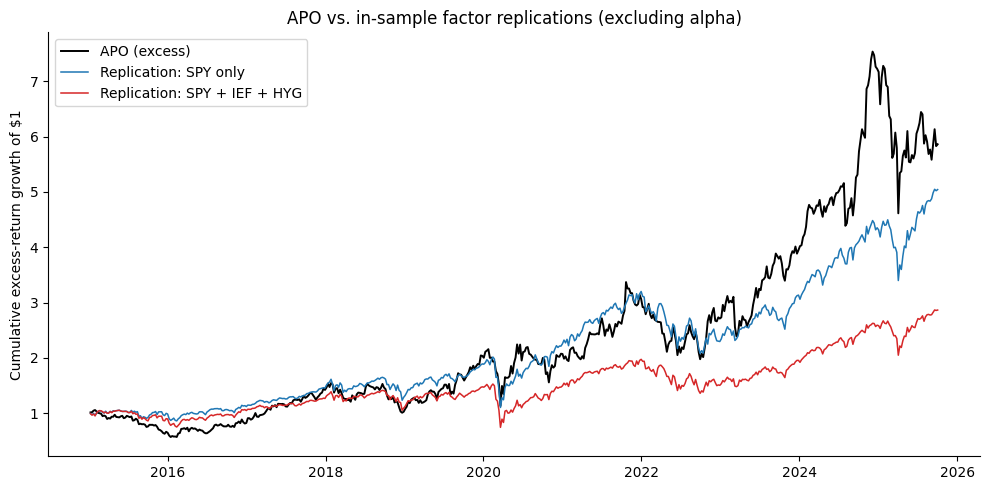

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot((1 + y_apo).cumprod(), color='black', lw=1.4, label='APO (excess)')
for (name, model), color in zip(fits.items(), ['tab:blue', 'tab:red']):
    replica = model.fittedvalues - model.params['const']   # factor exposures only, no alpha
    ax.plot((1 + replica).cumprod(), color=color, lw=1.1, label=f'Replication: {name}')
ax.set_ylabel('Cumulative excess-return growth of $1')
ax.set_title('APO vs. in-sample factor replications (excluding alpha)')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / 'c2_apo_replication.png', dpi=160)
plt.show()

**Can we replicate APO with SPY, IEF, and HYG?** Only partly.
- The three-asset replication explains **49.7%** of APO's weekly variance, compared with **46.6%** for SPY alone. Annualized tracking error falls only from 26.9% to 26.1%. About half of APO's risk is idiosyncratic and cannot be matched with these public assets.
- The bond factors are statistically significant. HYG enters long ($\beta \approx 0.93$, $t\approx5.1$) and IEF short ($\beta \approx -0.70$, $t\approx-4.0$), and the F-test rejects that they add nothing. Long high yield and short Treasuries is roughly a **credit-spread** position. This fits Apollo's large credit and insurance business (Athene). Once credit is included, the SPY beta falls from 1.48 to 1.07: part of what looked like equity beta was credit exposure.
- The replication tracks APO's broad cycles but misses a large cumulative gap (see plot). That gap is the alpha plus the idiosyncratic risk. Alpha rises from 4.9% to 10.0% per year in the three-asset model, but its t-stat is still only 1.2, so it is not significant. Since IEF and HYG returns here leave out coupons, and the replication is net long the higher-yielding HYG, the true alpha is likely **smaller** than shown.

**Compared with SPY alone:** adding IEF and HYG improves the fit a little (+3 pp of $R^2$, −0.8 pp of tracking error) and shows a real credit exposure. In practice, though, APO behaves like **levered equity (beta ≈ 1.5) with some credit tilt and a large idiosyncratic component**, and neither replication is close.